# Orientation mapping of a 4D-STEM scan

In a 4D-STEM scan the electron beam steps across the sample and records a diffraction pattern at
every point. If each pattern is indexed, finding the crystal's orientation there, the scan becomes
an **orientation map**: a picture of the grains, coloured by how each one is oriented. This
notebook makes one with pyEMAPS, step by step, from a synthetic scan of Aluminium grains whose
orientations are known, so you can see how well the map recovers them. It follows the
*al_orientmap.py* sample, one step per cell.

You'll:

1. generate a database of simulated diffraction patterns for Aluminium;
2. make a small scan of four grains with known orientations, and look at it;
3. choose the indexing settings for scan data;
4. map the scan's orientations, and read the map and its colour key;
5. compare the map with the true orientations, and save it.

**How it works.** `StackImage.mapOrientation` indexes every pattern of the scan on its own, as
`indexImage` indexes one pattern (see the [pattern indexing notebook](al_ediom.ipynb)): it finds
the diffraction peaks, matches them against the database, and turns the best match into an
orientation.

**Experimental.** Orientation mapping is new in pyEMAPS. It finds the right orientations on
simulated scans like this one, but it hasn't yet been validated against an independent
orientation map of real data, and its results depend on the peak search settings. Its parameters,
defaults and results may change in later releases.

**A licensed feature.** It needs an activated pyEMAPS license. `pyemaps -l trial`, run in a
terminal with an internet connection, activates a free 7-day trial; for a full license, contact
support@emlabsoftware.com. Step 1 checks it.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment. Mapping the scan takes about two minutes.

The [orientation maps section](https://emlab-solutions.github.io/pyemaps/user_guide/indexing.html#orientation-maps) of the
indexing guide covers the same ground.

## Step 1: Import pyEMAPS and check the license

`StackImage` holds experimental images and runs the 4D-STEM analyses, and `OrientationMap` holds
an orientation map. The *al_orientmap.py* sample that comes with pyEMAPS has the functions that
draw the synthetic scan; the notebook imports them as `demo`.

In [1]:
import os
import sys
import tempfile
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt

import pyemaps
from pyemaps import (EMC, Crystal, StackImage, OrientationMap, OM_INDEXED, write_im3,
                     stem4d)

print('pyEMAPS', version('pyemaps'))
if stem4d.check_license_once() == stem4d.LICENSE_ACTIVE:
    print('License: active')
else:
    print('No active license: run "pyemaps -l trial" in a terminal for a 7-day trial, '
          'or contact support@emlabsoftware.com.')

# The sample scripts that come with pyEMAPS, for the synthetic scan.
sys.path.insert(0, os.path.join(os.path.dirname(pyemaps.__file__), 'samples'))
import al_orientmap as demo

pyEMAPS 2.7.0
License: active


## Step 2: Generate the pattern database

`generateDPDB` simulates kinematic diffraction patterns of Aluminium over a range of orientations
and saves them in a database file. The range is the **standard triangle** between the [001],
[011] and [111] zone axes: for a cubic crystal every beam direction is equivalent, by symmetry,
to one inside it. Each pattern in the database is one beam direction; indexing finds the beam
direction and the in-plane rotation that match an experimental pattern best.

In [2]:
aluminium = Crystal.from_builtin('Aluminium')
ret, db_file = aluminium.generateDPDB(emc=EMC(zone=(0, 0, 1)), xa=(2, 0, 0), res=200)
print('Database:', os.path.basename(db_file) if ret == 0 else f'failed ({ret})')

*******************************************************************************
* The diffraction pattern database for Aluminium has been generated successfully
* and saved in:
* C:\pyemaps_data\dpdb\Aluminium-20261125115637.bin
*******************************************************************************
Database: Aluminium-20261125115637.bin


## Step 3: Make a synthetic scan

The scan is 12 x 12 points, with four grains. Each grain has a zone axis $[uvw]$ along the beam
and an in-plane rotation, and grows from a seed point: every scan point belongs to the grain whose
seed is nearest. The grains are listed in `demo.GRAINS`:

In [3]:
for zone, angle, seed in demo.GRAINS:
    print(f'zone axis {list(zone)}, turned {angle:5.1f} degrees, seed at scan point {seed}')

zone axis [1, 1, 1], turned  17.0 degrees, seed at scan point (2, 3)
zone axis [1, 1, 2], turned 141.0 degrees, seed at scan point (3, 10)
zone axis [1, 1, 4], turned 233.0 degrees, seed at scan point (9, 2)
zone axis [0, 1, 2], turned 302.0 degrees, seed at scan point (9, 9)


At each point, `demo.spot_pattern` draws the kinematic spot pattern of the grain's
orientation: the reflections $\mathbf g = (hkl)$ allowed in face-centred cubic Aluminium (all even
or all odd), close enough to the Ewald sphere, as Gaussian spots. To make it look more like real
data, each point's orientation is turned by a random 0.3 degree inside its grain, and the counts
get Poisson noise, as from a counting detector.

In [4]:
rng = np.random.default_rng(1)
patterns, truth, grain = demo.make_scan(rng)
print('patterns:', patterns.shape, '(scan points, rows, columns)')
print('true orientations:', truth.shape, '(scan rows, scan columns, 3 x 3 matrix)')

patterns: (144, 200, 200) (scan points, rows, columns)
true orientations: (12, 12, 3, 3) (scan rows, scan columns, 3 x 3 matrix)


## Step 4: Look at the scan

On the left, the grains; on the right, the middle of one pattern from each, on a square-root
scale so the weak spots show. Each grain sits at a zone axis, so its pattern is a regular net of
spots around the direct beam: six-fold at [111], and nets with fewer strong spots at [112], [114]
and [012]. The [012] pattern has the fewest, which makes it the hardest to index, as Step 5
shows.

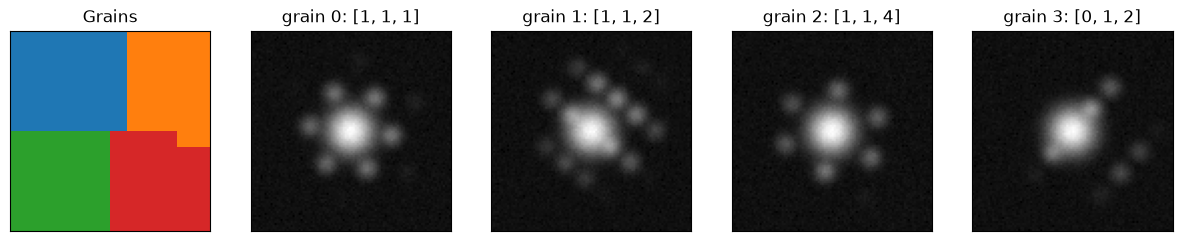

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(grain, cmap='tab10', vmin=0, vmax=9)
axes[0].set_title('Grains')
for g, (zone, angle, seed) in enumerate(demo.GRAINS):
    k = seed[0] * demo.SCAN[1] + seed[1]
    axes[g + 1].imshow(np.sqrt(patterns[k][50:150, 50:150]), cmap='gray')
    axes[g + 1].set_title(f'grain {g}: {list(zone)}')
for a in axes:
    a.set_xticks([])
    a.set_yticks([])
plt.show()

## Step 5: Choose the settings

The indexing settings are those of `indexImage`. The image measurements, the camera constant
*cc*, the pattern center and the peak width *sigma*, are known here from the simulation. Two
settings matter most for scans:

- *peak_threshold* tests how closely each peak's shape matches the search kernel. The default,
  0.825, suits clean patterns such as selected area diffraction; scan patterns are noisier, and
  it can miss their peaks.
- *min_snr* keeps only peaks that stand at least *min_snr* times the noise above the background
  around them, so a looser *peak_threshold* doesn't let the background in.

*sigma* is the peak width in pixels, about half the peaks' full width at half maximum. These spots
are drawn with a standard deviation of 3 pixels, so 3.0.

Try both on three points of each grain: the default, and the scan settings, 0.6 and *min_snr* 3.

In [6]:
SETTINGS = dict(cc=demo.CC, sigma=demo.SIGMA, img_center=demo.CENTER, rmin=10,
                search_box=10.0)
flat_grain = grain.ravel()
picks = [k for g in range(len(demo.GRAINS)) for k in np.flatnonzero(flat_grain == g)[:3]]
flat_truth = truth.reshape(-1, 3, 3)

def map_patterns(stack, **settings):
    '''Map a stack of patterns as one row of a scan.'''
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, 'patterns.im3')
        write_im3(path, stack)
        return StackImage(path).mapOrientation(db_file, scan_shape=(1, len(stack)),
                                               progress=False, **SETTINGS, **settings)

for name, settings in (('default', {}), ('scan settings', dict(peak_threshold=0.6, min_snr=3.0))):
    m = map_patterns(patterns[picks], **settings)
    right = [m.status[0, i] == OM_INDEXED
             and demo.misorientation(m.orientation[0, i], flat_truth[k]) < 1.0
             for i, k in enumerate(picks)]
    per_grain = ', '.join(f'{list(z)}: {sum(right[3 * g:3 * g + 3])}/3'
                          for g, (z, a, s) in enumerate(demo.GRAINS))
    print(f'{name:14s} {per_grain}')

Diffraction Database loaded successfully.
Dimension of stereo projection map: width =76, height=85


default        [1, 1, 1]: 3/3, [1, 1, 2]: 2/3, [1, 1, 4]: 3/3, [0, 1, 2]: 0/3
Diffraction Database loaded successfully.
Dimension of stereo projection map: width =76, height=85


scan settings  [1, 1, 1]: 3/3, [1, 1, 2]: 3/3, [1, 1, 4]: 3/3, [0, 1, 2]: 2/3


With the default threshold the noisy [012] patterns find too few peaks to index, and so does a
[112] pattern; the scan settings index all but one. On your own data, try a few settings on some
patterns, as here, before mapping a whole scan.

## Step 6: Map the whole scan

`mapOrientation` takes the scan's shape, `(rows, columns)`, and returns an `OrientationMap`.
It prints its progress; pressing the stop button (or Ctrl+C) stops it and returns the patterns done
so far.

In [7]:
with tempfile.TemporaryDirectory() as tmp:
    scan_file = os.path.join(tmp, 'al_scan.im3')
    write_im3(scan_file, patterns)
    omap = StackImage(scan_file).mapOrientation(db_file, scan_shape=demo.SCAN,
                                                peak_threshold=0.6, min_snr=3.0, **SETTINGS)
print(omap)

Diffraction Database loaded successfully.
Dimension of stereo projection map: width =76, height=85
Orientation map: 7 of 144 patterns, about 0.0 min left


Orientation map: 14 of 144 patterns, about 0.0 min left


Orientation map: 21 of 144 patterns, about 0.0 min left


Orientation map: 28 of 144 patterns, about 0.0 min left


Orientation map: 35 of 144 patterns, about 0.0 min left


Orientation map: 42 of 144 patterns, about 0.0 min left


... (12 outputs left out)

Orientation map: 133 of 144 patterns, about 0.0 min left


Orientation map: 140 of 144 patterns, about 0.0 min left


Orientation map: 144 of 144 patterns, about 0.0 min left


OrientationMap: 12 x 12 scan, 144 patterns: 139 indexed, 5 too few peaks; 131 reliable (reliability index >= 5)


Every pattern has a **status**: indexed, too few peaks, or indexing failed. An indexed
pattern also has a **reliability index**: above 5, the best match clearly beats the others.
`omap.reliable()` selects the patterns indexed reliably.

## Step 7: Read the map

`omap.show()` colours each point by its **beam direction in the crystal**, the zone axis the
beam is closest to, using the colour key on the right: the standard triangle, with [001] red,
[011] green and [111] blue. This is an **inverse pole figure** (IPF) colouring: instead of
showing where a crystal direction points in the sample, it shows which crystal direction the
sample's beam points along. Black points weren't indexed reliably.

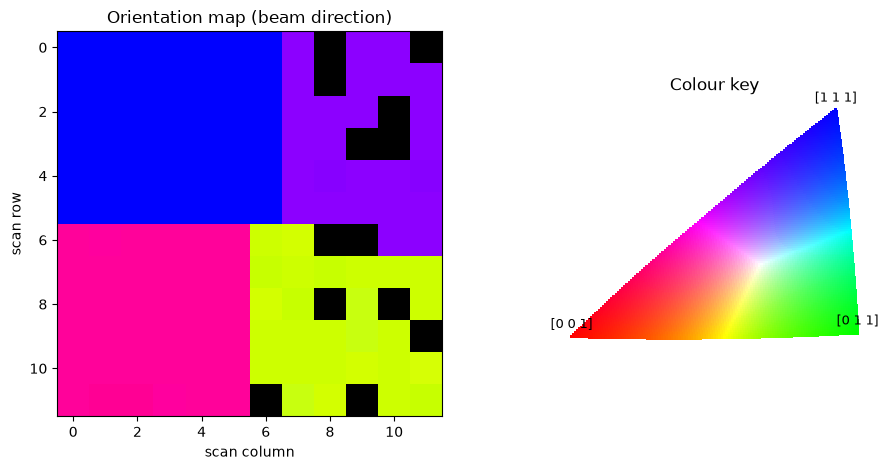

In [8]:
omap.show();

The reliability index at each point shows where the indexing is surest. The grains whose
patterns have few strong spots, [112] and [012], score lower, and their black points in the map
above are the ones below 5.

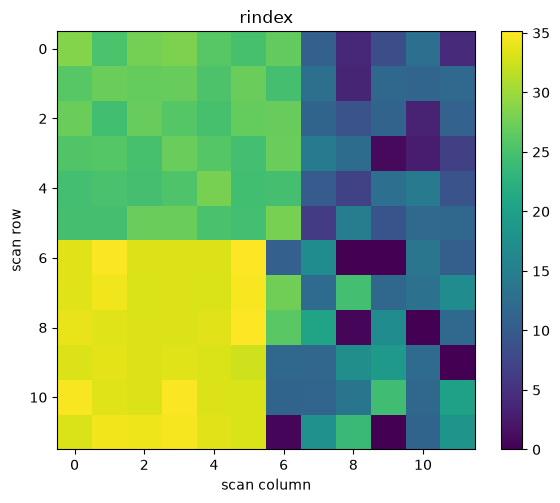

In [9]:
omap.show('rindex');

## Step 8: Compare with the truth

### The orientation matrix

Each indexed point has an orientation matrix $U$. It turns a vector's components in the crystal
frame, with $x$ along the crystal's $a$ axis, into its components in the sample frame, with $x$
along the pattern's columns, $y$ down its rows and $z$ along the beam:

$$\mathbf v_{\text{sample}} = U\,\mathbf v_{\text{crystal}}.$$

Its third row is the beam direction in crystal components, which the IPF colours show.

### Misorientation

The angle between two orientations $U_1$ and $U_2$ is the angle of the rotation that takes one to
the other, $U_1 U_2^{\mathsf T}$:

$$\theta = \arccos\frac{\operatorname{tr}\!\left(U_1 U_2^{\mathsf T}\right) - 1}{2}.$$

A cubic crystal looks the same after any of its 24 symmetry rotations $S$, so the misorientation
is the smallest angle over them. And a spot pattern from the zero-order Laue zone looks the same
after a 180 degree turn $E$ about the beam, so that is allowed too:

$$\theta = \min_{S,\,E}\ \arccos\frac{\operatorname{tr}\!\left(E\,U_1 S\,U_2^{\mathsf T}\right) - 1}{2}.$$

`demo.misorientation` computes it. Below, the true orientations and the mapped ones in the same
colours, and the angle between them at each point. Black points in the mapped panel weren't
indexed reliably, and white ones in the right-hand panel weren't indexed at all.

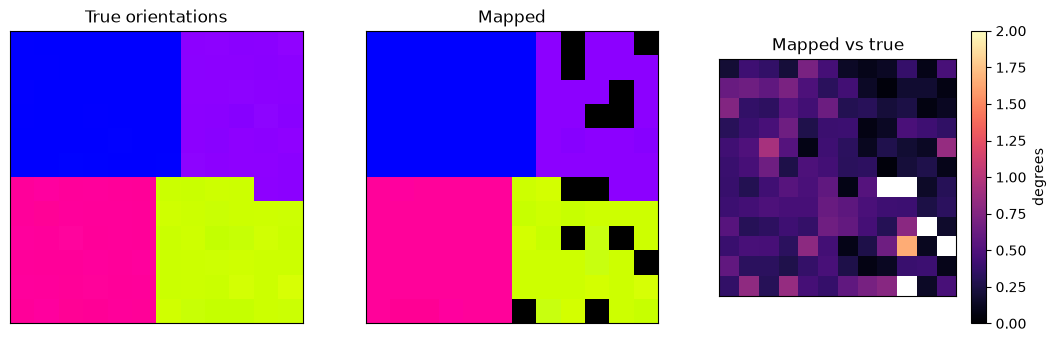

139 of 144 patterns indexed; within 1 degree of the truth: 138; median error 0.39 degrees


In [10]:
err = np.full(omap.scan_shape, np.nan)
for r, c in np.ndindex(omap.scan_shape):
    if omap.status[r, c] == OM_INDEXED:
        err[r, c] = demo.misorientation(omap.orientation[r, c], truth[r, c])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].imshow(demo.truth_map(omap, truth).ipf_colors(), interpolation='nearest')
axes[0].set_title('True orientations')
axes[1].imshow(omap.ipf_colors(), interpolation='nearest')
axes[1].set_title('Mapped')
im = axes[2].imshow(err, interpolation='nearest', cmap='magma', vmin=0, vmax=2)
fig.colorbar(im, ax=axes[2], label='degrees')
axes[2].set_title('Mapped vs true')
for a in axes:
    a.set_xticks([])
    a.set_yticks([])
plt.show()

ok = ~np.isnan(err)
print(f'{ok.sum()} of {err.size} patterns indexed; within 1 degree of the truth: '
      f'{np.sum(err[ok] < 1)}; median error {np.median(err[ok]):.2f} degrees')

The errors are a fraction of a degree: about the size of the 0.3 degree spread inside each
grain, and of the spacing of the database's orientations.

## Step 9: Look at one point

The map holds the beam direction as a zone axis, `beam_indices()`, scaled so the largest index is
1, and the orientation as **Bunge Euler angles** $(\varphi_1, \Phi, \varphi_2)$,
`euler_angles()`, as EBSD and other orientation mapping software report them. Take the seed point
of each grain: its zone axis should match the grain's, up to the cubic symmetry, which can swap
and change the sign of the indices.

In [11]:
beams, eulers = omap.beam_indices(), omap.euler_angles()
for zone, angle, (r, c) in demo.GRAINS:
    uvw = np.round(beams[r, c] * max(zone), 2)
    print(f'grain {list(zone)} at {(r, c)}: mapped zone axis {uvw.tolist()}, '
          f'Euler angles {np.round(eulers[r, c], 1).tolist()}')

grain [1, 1, 1] at (2, 3): mapped zone axis [0.98, 0.99, 1.0], Euler angles [126.4, 54.4, 44.7]
grain [1, 1, 2] at (3, 10): mapped zone axis [1.0, 1.0, 2.0], Euler angles [308.9, 35.3, 45.0]
grain [1, 1, 4] at (9, 2): mapped zone axis [0.99, 1.02, 4.0], Euler angles [280.1, 19.6, 44.2]
grain [0, 1, 2] at (9, 9): mapped zone axis [0.04, 1.03, 2.0], Euler angles [309.1, 27.3, 2.3]


## Step 10: Save the map

`save` writes the map to a NumPy *.npz* file, and `OrientationMap.load` reads it back, so a long
mapping run doesn't have to be repeated.

In [12]:
omap.save('al_orientation_map.npz')
again = OrientationMap.load('al_orientation_map.npz')
print(again)
print('same orientations:', np.array_equal(again.orientation, omap.orientation, equal_nan=True))

OrientationMap: 12 x 12 scan, 144 patterns: 139 indexed, 5 too few peaks; 131 reliable (reliability index >= 5)
same orientations: True


## Try it yourself

1. Change the grains: edit `demo.GRAINS` (zone axis, rotation, seed point) and rerun from Step 3.
   Try other zone axes, and see which ones index reliably.
2. Map the scan with the default settings, and see which grains go black.
3. Change *sigma* to 2.0 or 5.0 in `SETTINGS` and map again: too narrow or too wide a peak width
   loses peaks.
4. Make a bigger scan: set `demo.SCAN = (20, 20)` and rerun from Step 3. Mapping takes longer,
   about 0.03 seconds per pattern.

## Next

- The pattern indexing notebook, [al_ediom.ipynb](al_ediom.ipynb), which indexes one
  experimental pattern and checks the result by hand.
- The 4D-STEM imaging notebook, [adf.ipynb](adf.ipynb): bright field, dark field and masked
  images of a scan.
- The [orientation maps section](https://emlab-solutions.github.io/pyemaps/user_guide/indexing.html#orientation-maps) of the
  indexing guide, and the reference for
  [`mapOrientation`](https://emlab-solutions.github.io/pyemaps/api/images.html#pyemaps.stackimg.StackImage.mapOrientation).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 2, *The Geometry of CBED Patterns*, for zone axes and indexing in Steps 2 to 5.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3), a newer and
broader book by the same authors:

- chapter 3, *The Geometry of Electron Diffraction Patterns*, for zone axes and indexing in
  Steps 2 to 5;
- chapter 11, *Crystal Symmetry*, for the symmetry-equivalent orientations in Steps 8 and 9.